# Solubilidade e precipitação: o produto de solubilidade
### Funções inorgânicas — sais

**Objetivo:** Calcular solubilidade a partir de $K_{ps}$, aplicar o efeito do íon comum e entender a precipitação seletiva.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Dissolver um sal pouco solúvel é estabelecer um equilíbrio entre o sólido e os íons:

$$
\mathrm{A_xB_y(s) \rightleftharpoons x\,A^{n+}(aq) + y\,B^{m-}(aq)}
\qquad
\boxed{K_{ps} = [\mathrm{A^{n+}}]^x\,[\mathrm{B^{m-}}]^y}
$$

$K_{ps}$ é o **produto de solubilidade**: só depende da temperatura. A partir dele se calcula a solubilidade molar $s$ (mol/L):

| Estequiometria | Relação | Exemplo |
|---|---|---|
| 1:1 | $K_{ps} = s^2$ | AgCl, BaSO₄ |
| 1:2 / 2:1 | $K_{ps} = 4s^3$ | PbI₂, Ag₂CrO₄ |
| 1:3 / 3:1 | $K_{ps} = 27s^4$ | Al(OH)₃, Ag₃PO₄ |

A regra de decisão é o **produto iônico** $Q$:

$$
Q < K_{ps}\ \text{(insaturada)} \qquad
Q = K_{ps}\ \text{(saturada)} \qquad
Q > K_{ps}\ \text{(precipita)}
$$

Duas aplicações que caem em prova: **efeito do íon comum** (aumentar um dos íons diminui a solubilidade do sal) e **precipitação seletiva** (separar íons controlando a concentração do agente precipitante).

## 2. Exemplo resolvido passo a passo

**Solubilidade do $\mathrm{PbI_2}$** ($K_{ps} = 7{,}1\times10^{-9}$) em água pura e em solução de $\mathrm{KI}$ $0{,}10\ \mathrm{mol/L}$.

**Passo 1 — em água pura (1:2).**

$$
K_{ps} = [\mathrm{Pb^{2+}}][\mathrm{I^-}]^2 = s\,(2s)^2 = 4s^3
$$
$$
s = \sqrt[3]{\frac{7{,}1\times10^{-9}}{4}} = 1{,}2\times10^{-3}\ \mathrm{mol/L}
$$

**Passo 2 — em KI 0,10 mol/L (íon comum $\mathrm{I^-}$).**

Aqui $[\mathrm{I^-}] \approx 0{,}10 + 2s \approx 0{,}10$ (a contribuição do sal é desprezível):

$$
[\mathrm{Pb^{2+}}] = \frac{K_{ps}}{[\mathrm{I^-}]^2} = \frac{7{,}1\times10^{-9}}{0{,}010} = 7{,}1\times10^{-7}\ \mathrm{mol/L}
$$

**Passo 3 — comparar.**

$$
\frac{s_{\text{água}}}{s_{\text{KI}}} = \frac{1{,}2\times10^{-3}}{7{,}1\times10^{-7}} \approx 1700
$$

A presença de íon comum reduziu a solubilidade em **quase 1700 vezes**. É o princípio usado em análise química para precipitar o máximo possível de um íon antes de filtrar.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Kps, solubilidade e íon comum
KPS_PBI2 = 7.1e-9

def solubilidade_1_2(kps):
    """Sal do tipo AB2: Kps = 4 s^3."""
    return (kps / 4) ** (1 / 3)

s_agua = solubilidade_1_2(KPS_PBI2)
iodeto = 0.10
pb_em_ki = KPS_PBI2 / iodeto ** 2

print(f"Kps do PbI2 = {KPS_PBI2:.1e}")
print(f"s em água pura        = {s_agua:.2e} mol/L")
print(f"[Pb2+] com KI 0,10 M  = {pb_em_ki:.2e} mol/L")
print(f"redução de solubilidade: {s_agua / pb_em_ki:,.0f}x")
print(f"em massa (M = 461,0):  {s_agua * 461.0:.2e} g/L em água pura")

Kps do PbI2 = 7.1e-09
s em água pura        = 1.21e-03 mol/L
[Pb2+] com KI 0,10 M  = 7.10e-07 mol/L
redução de solubilidade: 1,705x
em massa (M = 461,0):  5.58e-01 g/L em água pura


## 4. Visualização

### 4.1 Iodeto de chumbo(II) em 3D — arraste para girar

O $\mathrm{PbI_2}$ é o precipitado **amarelo** clássico da análise de chumbo: um $\mathrm{Pb^{2+}}$ para cada dois $\mathrm{I^-}$. Gire a figura e conte os íons.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Pb+2].[I-].[I-]")

[16:36:17] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:17] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:17] UFFTYPER: Unrecognized atom type: Pb3+3 (0)
[16:36:17] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:17] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:17] UFFTYPER: Unrecognized atom type: Pb3+3 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Cromato de prata em 3D

O $\mathrm{Ag_2CrO_4}$ é o precipitado vermelho-tijolo usado na determinação de cloreto (método de Mohr). Também é 2:1, como o iodeto de chumbo.

In [4]:
molecula_3d("[Ag+].[Ag+].[O-][Cr](=O)(=O)[O-]")

[16:36:17] UFFTYPER: Unrecognized atom type: Ag5+1 (0)
[16:36:17] UFFTYPER: Unrecognized atom type: Ag5+1 (0)
[16:36:17] UFFTYPER: Unrecognized atom type: Cr3+3 (1)
[16:36:17] UFFTYPER: Unrecognized atom type: Ag5+1 (0)
[16:36:17] UFFTYPER: Unrecognized atom type: Ag5+1 (1)
[16:36:17] UFFTYPER: Unrecognized atom type: Cr3+3 (3)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

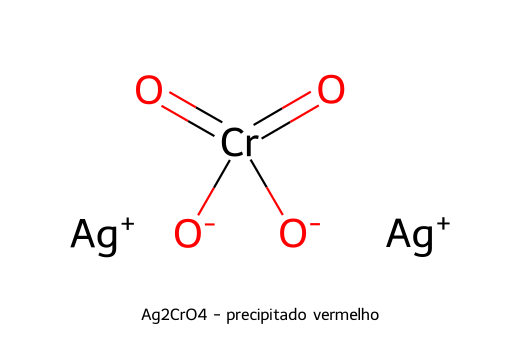

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Pb+2].[I-].[I-]", legenda="PbI2 - precipitado amarelo")
estrutura_2d("[Ag+].[Ag+].[O-][Cr](=O)(=O)[O-]", legenda="Ag2CrO4 - precipitado vermelho")

### 4.4 Comparando solubilidades de sais 1:1

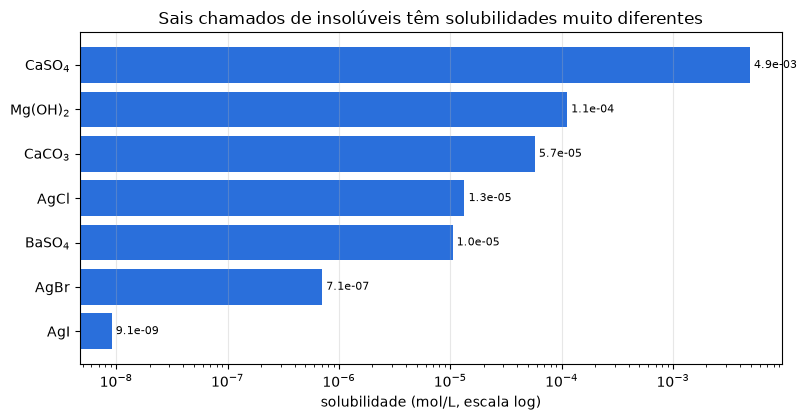

In [6]:
# @title Kps x solubilidade
import numpy as np
import matplotlib.pyplot as plt

sais = {
    "AgCl": 1.8e-10, "AgBr": 5.0e-13, "AgI": 8.3e-17,
    "BaSO$_4$": 1.1e-10, "CaSO$_4$": 2.4e-5, "CaCO$_3$": 3.3e-9,
    "Mg(OH)$_2$": 5.6e-12,
}
solubilidade = {}
for nome, kps in sais.items():
    if nome == "Mg(OH)$_2$":        # 1:2 -> 4s^3
        solubilidade[nome] = (kps / 4) ** (1 / 3)
    else:
        solubilidade[nome] = kps ** 0.5

nomes = list(solubilidade)
valores = [solubilidade[n] for n in nomes]
ordem = np.argsort(valores)

plt.figure(figsize=(8.2, 4.3))
plt.barh([nomes[i] for i in ordem], [valores[i] for i in ordem], color="#2a6fdb")
plt.xscale("log")
for i, indice in enumerate(ordem):
    plt.annotate(f"{valores[indice]:.1e}", (valores[indice], i), xytext=(3, 0),
                 textcoords="offset points", va="center", fontsize=8)
plt.xlabel("solubilidade (mol/L, escala log)")
plt.title("Sais chamados de insolúveis têm solubilidades muito diferentes")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5 O efeito do íon comum

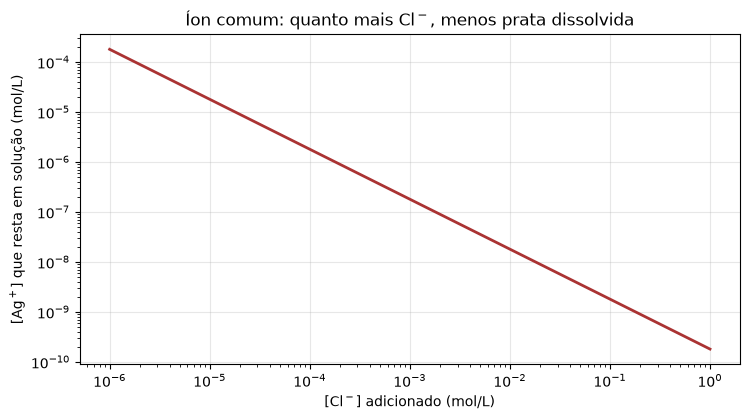

In [7]:
# @title Solubilidade do AgCl com NaCl adicionado
kps_agcl = 1.8e-10
cloretos = np.logspace(-6, 0, 100)
prata = kps_agcl / cloretos

plt.figure(figsize=(7.6, 4.3))
plt.plot(cloretos, prata, color="#a33", linewidth=2)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("[Cl$^-$] adicionado (mol/L)")
plt.ylabel("[Ag$^+$] que resta em solução (mol/L)")
plt.title("Íon comum: quanto mais Cl$^-$, menos prata dissolvida")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Precipitação seletiva

haleto          Kps   [X-] para precipitar
I-          8.3e-17                8.3e-15 mol/L
Br-         5.0e-13                5.0e-11 mol/L
Cl-         1.8e-10                1.8e-08 mol/L


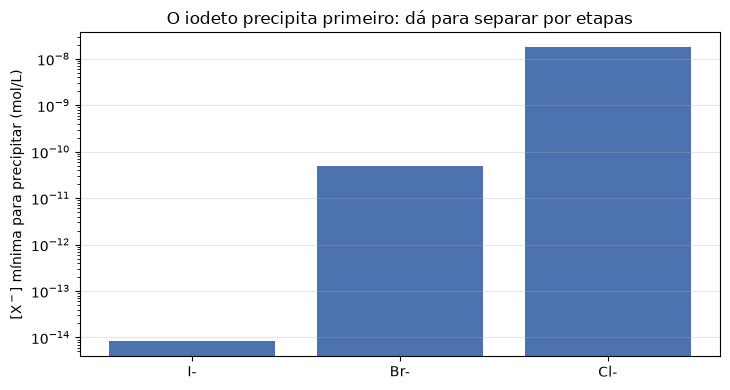

In [8]:
# @title Separando íons pela concentração do precipitante
haletos = {"I-": 8.3e-17, "Br-": 5.0e-13, "Cl-": 1.8e-10}   # Kps dos AgX
ag_prata = 0.010        # mol/L de Ag+ disponível

print(f"{'haleto':8s} {'Kps':>10s} {'[X-] para precipitar':>22s}")
for nome, kps in haletos.items():
    print(f"{nome:8s} {kps:10.1e} {kps / ag_prata:22.1e} mol/L")

plt.figure(figsize=(7.4, 4.0))
plt.bar(list(haletos), [kps / ag_prata for kps in haletos.values()], color="#4c72b0")
plt.yscale("log")
plt.ylabel("[X$^-$] mínima para precipitar (mol/L)")
plt.title("O iodeto precipita primeiro: dá para separar por etapas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- $K_{ps}$ não é solubilidade: para sais com estequiometrias diferentes, é preciso converter. O $\mathrm{Mg(OH)_2}$ tem $K_{ps}$ menor que o do $\mathrm{CaSO_4}$, mas solubilidade comparável em mol/L.
- Íon comum desloca o equilíbrio para o sólido: é a alavanca usada em gravimetria ("lavar o precipitado" com solução diluída do precipitante).
- Precipitação seletiva funciona porque os $K_{ps}$ diferem em ordens de grandeza: o iodeto sai primeiro, depois o brometo, depois o cloreto.
- Aumentar a temperatura quase sempre aumenta a solubilidade (com exceções), e $K_{ps}$ muda com $T$.

## 6. Exercício de fixação

A $K_{ps}$ do $\mathrm{Ca(OH)_2}$ é $5{,}5\times10^{-6}$. Qual é o pH de uma solução saturada dessa base? (Considere 25 °C.)

In [9]:
# @title Exercício
KPS_CAOH2 = 5.5e-6
s_ex = (KPS_CAOH2 / 4) ** (1 / 3)          # 1:2 -> 4s^3
oh_ex = 2 * s_ex
ph_ex = 14 + __import__("math").log10(oh_ex)
print(f"solubilidade s = {s_ex:.2e} mol/L")
print(f"[OH-] = {oh_ex:.2e} mol/L")
print(f"pH da solução saturada = {ph_ex:.2f}")
print("(é a 'água de cal', que fica básica mesmo com pouquíssimo sólido dissolvido)")

solubilidade s = 1.11e-02 mol/L
[OH-] = 2.22e-02 mol/L
pH da solução saturada = 12.35
(é a 'água de cal', que fica básica mesmo com pouquíssimo sólido dissolvido)


## 7. Resumo

- $K_{ps} = [\mathrm{A}]^x[\mathrm{B}]^y$ descreve o equilíbrio sólido/solução.
- solubilidade: 1:1 → $s=\sqrt{K_{ps}}$; 1:2 → $s=\sqrt[3]{K_{ps}/4}$.
- $Q > K_{ps}$: precipita; $Q < K_{ps}$: dissolve.
- Íon comum diminui a solubilidade (desloca o equilíbrio).
- Precipitação seletiva separa íons com $K_{ps}$ muito diferentes.

## Referências

- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.
- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- VOGEL, A. I. *Química Analítica Qualitativa*. Mestre Jou.